# Klasyfikacja kierunku zmian EUR/USD
### Sieć neuronowa w PyTorch oraz Random Forest, SVC i regresja logistyczna

**Cel:** przewidzieć, czy kolejny kurs referencyjny EUR/USD będzie wyższy od obecnego.
To ćwiczenie klasyfikacji binarnej stanowi punkt wyjścia do pracy magisterskiej o prognozowaniu
kursów walutowych z wykorzystaniem Transformerów i danych rynkowych oraz makroekonomicznych.

**Plan:** dane → podział czasowy → EDA → cechy i preprocessing → MLP → strojenie → porównanie na teście.
Wszystkie wyniki poniżej powstają z rzeczywistych danych, bez założenia, że sieć musi wygrać.

Uruchamiaj komórki po kolei (**Restart Kernel and Run All**). Python 3.11 lub 3.12 jest zalecany.
Przy pierwszym uruchomieniu odkomentuj instalację w kolejnej komórce i w razie potrzeby zrestartuj kernel.
Obliczenia na CPU mogą potrwać kilka minut.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import copy
import hashlib
import io
import json
import platform
import random
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2})
DATA_DIR = Path('data')
RESULTS_DIR = Path('results')
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
print({'python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'torch': torch.__version__})


Matplotlib is building the font cache; this may take a moment.


{'python': '3.12.0', 'numpy': '2.5.3', 'pandas': '2.3.3', 'sklearn': '1.9.1', 'torch': '2.14.1'}


## 1. Dane publiczne i definicja eksperymentu

Źródło: [ECB – euro foreign exchange reference rates](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.en.html),
[archiwum CSV](https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip).
USD oznacza liczbę dolarów za 1 EUR. ECB zwykle publikuje kursy około 16:00 CET w dni robocze
z wyłączeniem dni zamknięcia TARGET. To kursy referencyjne, nie ceny zamknięcia ani kursy transakcyjne.

Badamy okres **2005–2025**. Prognoza powstaje po publikacji kursu w dniu t, a dotyczy kolejnej
obserwacji ECB (nie zawsze kolejnego dnia kalendarzowego).

\(y_t = 1[P_{t+1} > P_t]\). Klasa 0 obejmuje spadek i brak zmiany.
Ostatni wiersz bez znanego wyniku usuwamy, zamiast przypisywać mu 0.

Archiwum jest zapisywane lokalnie. Kolejne uruchomienia używają tej samej kopii;
SHA-256 dokumentuje dokładny plik. To współczesna kopia historii, nie baza historycznych
wersji publikacji. Ścisłe badanie point-in-time w magisterce wymaga także audytu korekt źródła.


In [2]:
URL = 'https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip'
archive = DATA_DIR / 'eurofxref-hist.zip'
if not archive.exists():
    request = urllib.request.Request(URL, headers={'User-Agent': 'EURUSD academic notebook'})
    with urllib.request.urlopen(request, timeout=60) as response:
        payload = response.read()
    with zipfile.ZipFile(io.BytesIO(payload)) as z:
        assert any(n.endswith('.csv') for n in z.namelist())
    archive.write_bytes(payload)

with zipfile.ZipFile(archive) as z:
    csv_name = next(n for n in z.namelist() if n.endswith('.csv'))
    raw = pd.read_csv(z.open(csv_name))
raw.columns = raw.columns.str.strip()
rates = raw[['Date', 'USD']].copy()
rates['Date'] = pd.to_datetime(rates['Date'], errors='raise')
rates['USD'] = pd.to_numeric(rates['USD'], errors='coerce')
rates = rates.sort_values('Date').set_index('Date').loc['2005-01-01':'2025-12-31']
assert rates.index.is_unique, 'Zduplikowane daty wymagają wyjaśnienia.'
assert rates.index.is_monotonic_increasing
assert (rates['USD'].dropna() > 0).all()
print('Brakujące kursy:', int(rates['USD'].isna().sum()))
assert rates['USD'].notna().all(), 'Nie imputujemy kursu docelowego; sprawdź dane źródłowe.'
manifest = {'source': URL, 'sha256': hashlib.sha256(archive.read_bytes()).hexdigest(),
            'analysis_start': str(rates.index.min().date()),
            'analysis_end': str(rates.index.max().date()), 'observations': len(rates),
            'run_utc': datetime.now(timezone.utc).isoformat()}
(RESULTS_DIR / 'data_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(manifest)


Brakujące kursy: 0
{'source': 'https://www.ecb.europa.eu/stats/eurofxref/eurofxref-hist.zip', 'sha256': '9d2c7ecc33b01c9b18c28ff10ddcf036901ee6a5d8637916d599864b64eb1a97', 'analysis_start': '2005-01-03', 'analysis_end': '2025-12-31', 'observations': 5376, 'run_utc': '2026-10-04T12:29:42.275389+00:00'}


## 2. Cechy historyczne i podział chronologiczny

Stopa zwrotu to `log(P_t / P_(t-1))`. `return_lag_0` jest znana w chwili prognozy:
uwzględnia już opublikowany kurs dnia t. Pozostałe cechy wykorzystują tylko bieżącą i wcześniejsze obserwacje.
Okna 5 i 20 oznaczają liczbę publikacji, a nie dni kalendarzowych.
Nie uzupełniamy weekendów sztucznymi kursami i nie usuwamy ekstremalnych zmian tylko dlatego, że są duże.

Ostatnie 20% próbek odkładamy jako **test**. W pierwszych 80% ostatnie 20% służy jako
**walidacja** (około 64/16/20 całego zbioru). To pojedynczy, chronologiczny holdout walidacyjny.
Usuwamy próbki z końców treningu i walidacji, których etykieta sięga następnego zbioru.
EDA i wybór parametrów nie korzystają z testu. Walk-forward jest możliwym rozszerzeniem do magisterki.


In [3]:
def make_features(prices):
    p = prices['USD']
    r = np.log(p / p.shift(1))
    features = pd.DataFrame(index=prices.index)
    for lag in range(5):
        features[f'return_lag_{lag}'] = r.shift(lag)
    for window in (5, 20):
        features[f'momentum_{window}'] = np.log(p / p.shift(window))
        features[f'volatility_{window}'] = r.rolling(window).std()
        features[f'ma_distance_{window}'] = p / p.rolling(window).mean() - 1
    features['weekday'] = features.index.dayofweek
    return features

X_all = make_features(rates)
future_return = np.log(rates['USD'].shift(-1) / rates['USD'])
label_date = pd.Series(rates.index, index=rates.index).shift(-1)
valid = X_all.notna().all(axis=1) & future_return.notna()
X = X_all.loc[valid].copy()
y = (future_return.loc[valid] > 0).astype('int64').rename('target')
label_date = label_date.loc[valid]

n_development = int(len(X) * .8)
n_train = int(n_development * .8)
validation_start = X.index[n_train]
test_start = X.index[n_development]
train_idx = X.index[(X.index < validation_start) & (label_date < validation_start)]
val_idx = X.index[(X.index >= validation_start) & (X.index < test_start)
                  & (label_date < test_start)]
test_idx = X.index[X.index >= test_start]
X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_val, y_val = X.loc[val_idx], y.loc[val_idx]
X_test, y_test = X.loc[test_idx], y.loc[test_idx]
assert label_date.loc[train_idx].max() < val_idx.min()
assert label_date.loc[val_idx].max() < test_idx.min()
assert set(train_idx).isdisjoint(test_idx)
assert y_train.nunique() == y_val.nunique() == 2

split_table = pd.DataFrame([
    {'zbiór': name, 'od': idx.min().date(), 'do': idx.max().date(), 'n': len(idx)}
    for name, idx in [('trening', train_idx), ('walidacja', val_idx), ('test', test_idx)]
])
display(split_table)
split_table.to_csv(RESULTS_DIR / 'splits.csv', index=False)

# Kontrola przyczynowości: usunięcie przyszłości nie zmienia wcześniejszych cech.
cut = rates.index[len(rates) // 2]
pd.testing.assert_frame_equal(make_features(rates.loc[:cut]), make_features(rates).loc[:cut])
print('Kontrole chronologii i przyczynowości cech: OK')


,zbiór,od,do,n
0,trening,2005-01-31,2018-06-19,3426
1,walidacja,2018-06-21,2021-10-22,856
2,test,2021-10-26,2025-12-30,1071


Kontrole chronologii i przyczynowości cech: OK


## 3. EDA — tylko okres treningowy

Sprawdzamy trend kursu, rozkład stóp zwrotu, częstość klas i korelacje.
Korelacja cech między sobą nie dowodzi ich zdolności prognostycznej.
Brak publikacji w weekendy i święta jest naturalny; nietypowe długie przerwy wymagają sprawdzenia.


,count,mean,std,min,25%,50%,75%,max
return_lag_0,3426.0,-0.000036,0.006066,-0.047354,-0.003266,0.000077,0.003298,0.040377
return_lag_1,3426.0,-0.000034,0.006065,-0.047354,-0.003262,0.000077,0.003298,0.040377
return_lag_2,3426.0,-0.000033,0.006065,-0.047354,-0.003262,0.000077,0.003298,0.040377
return_lag_3,3426.0,-0.000031,0.006062,-0.047354,-0.003256,0.000077,0.003298,0.040377
return_lag_4,3426.0,-0.000031,0.006062,-0.047354,-0.003256,0.000077,0.003298,0.040377
momentum_5,3426.0,-0.000164,0.013564,-0.074521,-0.008074,0.000000,0.008376,0.100764
volatility_5,3426.0,0.005343,0.002865,0.000551,0.003428,0.004827,0.006594,0.033223
ma_distance_5,3426.0,-0.000061,0.006648,-0.032353,-0.004162,0.000111,0.003902,0.055840
momentum_20,3426.0,-0.000673,0.027663,-0.150378,-0.016503,0.000113,0.016898,0.153034
volatility_20,3426.0,0.005662,0.002150,0.001654,0.004326,0.005272,0.006578,0.020053


,liczba,udział
target,,
0,1697,0.49533
1,1729,0.50467


Przerwy między publikacjami (dni):


Date
1.0    2729
2.0      11
3.0     674
4.0      13
5.0      18
Name: count, dtype: int64

Odsetek zerowych zmian w treningu: 0.007589025102159953


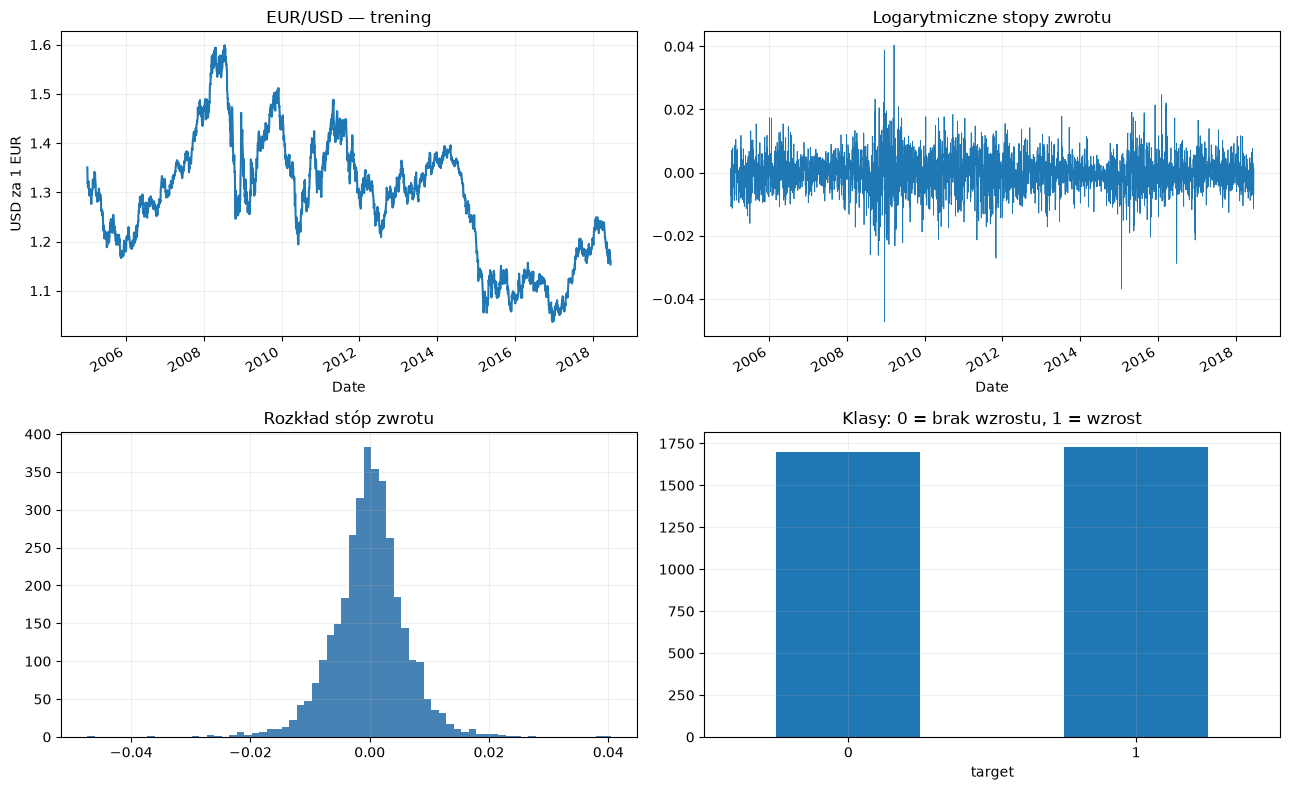

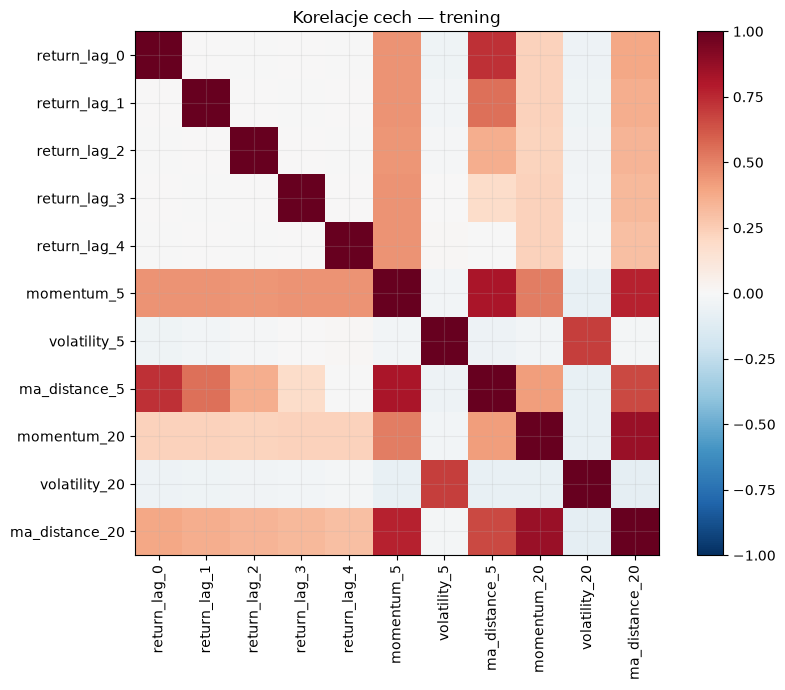

In [4]:
train_rates = rates.loc[:train_idx.max(), 'USD']
train_returns = np.log(train_rates / train_rates.shift(1)).dropna()
display(X_train.describe().T)
display(y_train.value_counts().reindex([0, 1], fill_value=0).rename('liczba').to_frame()
        .assign(udział=lambda t: t['liczba'] / t['liczba'].sum()))
print('Przerwy między publikacjami (dni):')
display(train_rates.index.to_series().diff().dt.days.value_counts().sort_index())
print('Odsetek zerowych zmian w treningu:', (future_return.loc[train_idx] == 0).mean())

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
train_rates.plot(ax=axes[0, 0], title='EUR/USD — trening', ylabel='USD za 1 EUR')
train_returns.plot(ax=axes[0, 1], title='Logarytmiczne stopy zwrotu', linewidth=.6)
axes[1, 0].hist(train_returns, bins=70, color='steelblue')
axes[1, 0].set_title('Rozkład stóp zwrotu')
y_train.value_counts().reindex([0, 1]).plot.bar(ax=axes[1, 1], rot=0)
axes[1, 1].set_title('Klasy: 0 = brak wzrostu, 1 = wzrost')
fig.tight_layout()
plt.show()

corr = X_train.drop(columns='weekday').corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im, ax=ax)
ax.set_title('Korelacje cech — trening')
fig.tight_layout()
plt.show()


## 4. Preprocessing bez wycieku informacji

Cechy liczbowe standaryzujemy do średniej 0 i odchylenia 1 według **treningu**.
Dzień tygodnia kodujemy one-hot, bez sugerowania porządku liczbowego.
Skaler nie jest dopasowywany do walidacji ani testu. Braki wynikające z początku okien zostały
usunięte przed podziałem; nie stosujemy imputacji korzystającej z przyszłości.


In [5]:
numeric_columns = [c for c in X.columns if c != 'weekday']
def make_preprocessor():
    return ColumnTransformer([
        ('numeric', StandardScaler(), numeric_columns),
        ('calendar', OneHotEncoder(categories=[list(range(5))], handle_unknown='ignore',
                                   sparse_output=False), ['weekday'])
    ])

preprocessor = make_preprocessor()
a_train = preprocessor.fit_transform(X_train).astype('float32')
a_val = preprocessor.transform(X_val).astype('float32')
assert np.isfinite(a_train).all() and np.isfinite(a_val).all()
print('Kształt wejścia:', a_train.shape)
print('Cechy po transformacji:', list(preprocessor.get_feature_names_out()))


Kształt wejścia: (3426, 16)
Cechy po transformacji: ['numeric__return_lag_0', 'numeric__return_lag_1', 'numeric__return_lag_2', 'numeric__return_lag_3', 'numeric__return_lag_4', 'numeric__momentum_5', 'numeric__volatility_5', 'numeric__ma_distance_5', 'numeric__momentum_20', 'numeric__volatility_20', 'numeric__ma_distance_20', 'calendar__weekday_0', 'calendar__weekday_1', 'calendar__weekday_2', 'calendar__weekday_3', 'calendar__weekday_4']


## 5. Sieć MLP i binary cross-entropy

MLP (*multilayer perceptron*) ma jedną lub dwie warstwy ukryte z ReLU i opcjonalnym dropout.
Warstwa końcowa zwraca jeden logit. `BCEWithLogitsLoss` łączy sigmoid i binary cross-entropy
w numerycznie stabilny sposób — **nie dodajemy sigmoid przed tą funkcją straty**.
Sigmoid stosujemy dopiero do obliczenia prawdopodobieństwa wzrostu.

Adam aktualizuje wagi, a early stopping wybiera epokę z najmniejszą stratą walidacyjną.
Próg klasyfikacji ustalamy z góry na 0.5. Parametry porównujemy według **macro-F1**, aby uwzględnić
obie klasy; raportujemy również wymagany F1 dla klasy wzrostowej.
Mini-batche można mieszać wewnątrz treningu: każdy wiersz zawiera gotowe cechy historyczne,
a MLP nie przenosi stanu między wierszami. Podział między zbiorami pozostaje chronologiczny.


In [6]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden, dropout):
        super().__init__()
        layers = []
        previous = input_size
        for width in hidden:
            layers.extend([nn.Linear(previous, width), nn.ReLU(), nn.Dropout(dropout)])
            previous = width
        layers.append(nn.Linear(previous, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x).squeeze(-1)


def train_mlp(config, max_epochs=100, patience=12):
    torch.manual_seed(SEED)
    model = MLP(a_train.shape[1], config['hidden'], config['dropout'])
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    tx, ty = torch.from_numpy(a_train), torch.tensor(y_train.to_numpy(), dtype=torch.float32)
    vx, vy = torch.from_numpy(a_val), torch.tensor(y_val.to_numpy(), dtype=torch.float32)
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(tx, ty), batch_size=config['batch_size'],
                        shuffle=True, generator=generator)
    best_loss, best_epoch, stale, best_state = float('inf'), 0, 0, None
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            train_loss = criterion(model(tx), ty).item()
            val_loss = criterion(model(vx), vy).item()
        history.append({'epoch': epoch, 'train_bce': train_loss, 'val_bce': val_loss})
        if val_loss < best_loss - 1e-5:
            best_loss, best_epoch, stale = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        if stale >= patience:
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch


def mlp_probability(model, array):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(array.astype('float32')))).numpy()


## 6. Strojenie hiperparametrów na walidacji

Sprawdzamy małą siatkę 16 konfiguracji: architekturę, dropout, learning rate i batch size.
Limit epok i cierpliwość early stopping są wspólne. To demonstracyjny budżet strojenia,
nie dowód znalezienia globalnie najlepszych parametrów.


MLP 01/16: macro-F1=0.4567, epoka=4
MLP 02/16: macro-F1=0.4630, epoka=1
MLP 03/16: macro-F1=0.4889, epoka=4
MLP 04/16: macro-F1=0.4717, epoka=1
MLP 05/16: macro-F1=0.4548, epoka=4
MLP 06/16: macro-F1=0.5028, epoka=4
MLP 07/16: macro-F1=0.4630, epoka=4
MLP 08/16: macro-F1=0.4646, epoka=2
MLP 09/16: macro-F1=0.4449, epoka=4
MLP 10/16: macro-F1=0.4593, epoka=1
MLP 11/16: macro-F1=0.4997, epoka=1
MLP 12/16: macro-F1=0.4338, epoka=1
MLP 13/16: macro-F1=0.4278, epoka=6
MLP 14/16: macro-F1=0.4971, epoka=4
MLP 15/16: macro-F1=0.5018, epoka=1
MLP 16/16: macro-F1=0.5040, epoka=4


,batch_size,dropout,hidden,lr,best_epoch,val_macro_f1,val_bce
15,64,0.2,"(32, 16)",0.003,4,0.503980,0.693033
5,32,0.2,"(16,)",0.003,4,0.502838,0.694433
14,64,0.2,"(32, 16)",0.001,1,0.501849,0.693290
10,64,0.0,"(32, 16)",0.001,1,0.499664,0.693446
13,64,0.2,"(16,)",0.003,4,0.497125,0.693976
2,32,0.0,"(32, 16)",0.001,4,0.488914,0.693255
3,32,0.0,"(32, 16)",0.003,1,0.471659,0.692897
7,32,0.2,"(32, 16)",0.003,2,0.464588,0.692566
1,32,0.0,"(16,)",0.003,1,0.463005,0.694527
6,32,0.2,"(32, 16)",0.001,4,0.462962,0.693099


Wybrane parametry: {'batch_size': 64, 'dropout': 0.2, 'hidden': (32, 16), 'lr': 0.003}


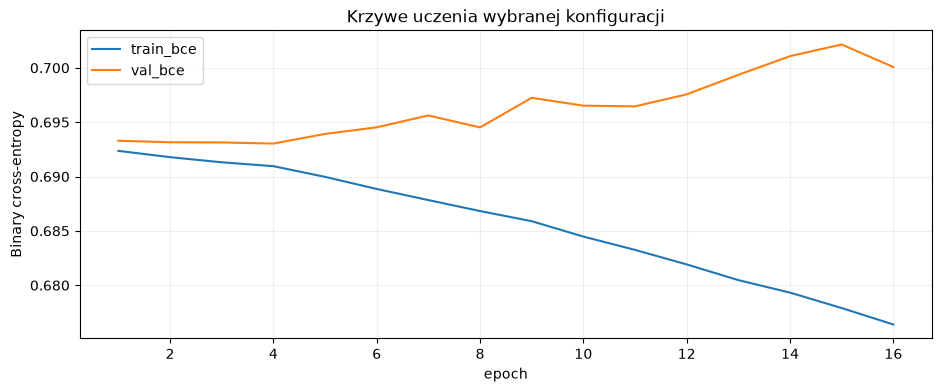

In [7]:
mlp_grid = list(ParameterGrid({'hidden': [(16,), (32, 16)], 'dropout': [0.0, 0.2],
                              'lr': [0.001, 0.003], 'batch_size': [32, 64]}))
mlp_rows = []
best_mlp, best_history, best_config = None, None, None
best_key = (-np.inf, -np.inf)
for i, config in enumerate(mlp_grid, 1):
    model, history, epoch = train_mlp(config)
    prob = mlp_probability(model, a_val)
    score = f1_score(y_val, prob >= .5, average='macro', zero_division=0)
    best_bce = float(history.loc[history['epoch'] == epoch, 'val_bce'].iloc[0])
    mlp_rows.append({**config, 'best_epoch': epoch, 'val_macro_f1': score, 'val_bce': best_bce})
    if (score, -best_bce) > best_key:
        best_key = (score, -best_bce)
        best_mlp, best_history, best_config = model, history, config.copy()
    print(f'MLP {i:02d}/{len(mlp_grid)}: macro-F1={score:.4f}, epoka={epoch}')
mlp_search = pd.DataFrame(mlp_rows).sort_values('val_macro_f1', ascending=False)
display(mlp_search)
mlp_search.to_csv(RESULTS_DIR / 'mlp_search.csv', index=False)
print('Wybrane parametry:', best_config)
best_history.plot(x='epoch', y=['train_bce', 'val_bce'], ylabel='Binary cross-entropy',
                  title='Krzywe uczenia wybranej konfiguracji')
plt.show()


## 7. Modele porównawcze

Wszystkie modele mają te same cechy oraz daty treningu, walidacji i testu.
Dla regresji logistycznej, Random Forest i SVC wybieramy parametry według walidacyjnego macro-F1.
Każdy pipeline dopasowuje preprocessing tylko na treningu. Skalowanie nie jest konieczne dla lasu,
ale zachowujemy ten sam zestaw przekształconych cech.
DummyClassifier przewiduje klasę większościową z treningu i wyznacza podstawowy punkt odniesienia.
Nie wymuszamy równej liczby konfiguracji, więc porównanie nie jest benchmarkiem równych budżetów.


In [8]:
search_spaces = {
    'Logistic regression': (LogisticRegression(max_iter=2000, random_state=SEED),
                            {'model__C': [0.01, 0.1, 1.0, 10.0]}),
    'Random Forest': (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2),
                       {'model__max_depth': [3, 6, None], 'model__min_samples_leaf': [10, 30]}),
    'SVC': (SVC(kernel='rbf'), {'model__C': [0.1, 1.0, 10.0], 'model__gamma': ['scale', 0.01]})
}
selected_models = {}
validation_scores = {'MLP': best_key[0]}
classic_rows = []
for name, (estimator, grid) in search_spaces.items():
    best_score, chosen = -np.inf, None
    for params in ParameterGrid(grid):
        pipeline = Pipeline([('preprocess', make_preprocessor()),
                             ('model', copy.deepcopy(estimator))])
        pipeline.set_params(**params)
        pipeline.fit(X_train, y_train)
        score = f1_score(y_val, pipeline.predict(X_val), average='macro', zero_division=0)
        classic_rows.append({'model': name, 'params': str(params), 'val_macro_f1': score})
        if score > best_score:
            best_score, chosen = score, pipeline
    selected_models[name] = chosen
    validation_scores[name] = best_score
    print(f'{name}: najlepszy walidacyjny macro-F1 = {best_score:.4f}')
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
selected_models['Majority baseline'] = dummy
validation_scores['Majority baseline'] = f1_score(y_val, dummy.predict(X_val), average='macro', zero_division=0)
display(pd.DataFrame(classic_rows).sort_values(['model', 'val_macro_f1'], ascending=[True, False]))
pd.DataFrame(classic_rows).to_csv(RESULTS_DIR / 'classic_search.csv', index=False)
selected_name = max(validation_scores, key=validation_scores.get)
print('Model wskazany przed otwarciem testu:', selected_name)


Logistic regression: najlepszy walidacyjny macro-F1 = 0.4341
Random Forest: najlepszy walidacyjny macro-F1 = 0.4918
SVC: najlepszy walidacyjny macro-F1 = 0.5036


,model,params,val_macro_f1
2,Logistic regression,{'model__C': 1.0},0.434149
3,Logistic regression,{'model__C': 10.0},0.434149
1,Logistic regression,{'model__C': 0.1},0.429771
0,Logistic regression,{'model__C': 0.01},0.405675
8,Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.491767
9,Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.467454
7,Random Forest,"{'model__max_depth': 6, 'model__min_samples_le...",0.463092
6,Random Forest,"{'model__max_depth': 6, 'model__min_samples_le...",0.444348
4,Random Forest,"{'model__max_depth': 3, 'model__min_samples_le...",0.421054
5,Random Forest,"{'model__max_depth': 3, 'model__min_samples_le...",0.418368


Model wskazany przed otwarciem testu: MLP


## 8. Jednorazowa ocena końcowa na teście

Dopiero teraz obliczamy wyniki testowe. Zachowujemy modele wytrenowane na treningu;
nie douczamy ich na walidacji, aby dla wszystkich utrzymać identyczny schemat oceny.
Nie zmieniamy już hiperparametrów, cech ani progu po obejrzeniu testu.

Precision, recall i F1 odnoszą się do klasy **1 = wzrost**. Macro-F1 uśrednia F1 obu klas.
Balanced accuracy uśrednia recall obu klas. ROC-AUC wykorzystuje wynik ciągły — dla SVC
jest to `decision_function`, nie skalibrowane prawdopodobieństwo.


,val_macro_f1,accuracy,precision,recall,f1,macro_f1,balanced_accuracy,roc_auc
model,,,,,,,,
MLP,0.5040,0.4865,0.4865,0.5065,0.4963,0.4863,0.4865,0.4837
Logistic regression,0.4341,0.4911,0.4928,0.6430,0.5580,0.4792,0.4913,0.4833
Random Forest,0.4918,0.4986,0.4983,0.5645,0.5294,0.4964,0.4987,0.5074
SVC,0.5036,0.5154,0.5132,0.5832,0.5459,0.5132,0.5155,0.5134
Majority baseline,0.3265,0.4995,0.4995,1.0000,0.6663,0.3331,0.5000,0.5000


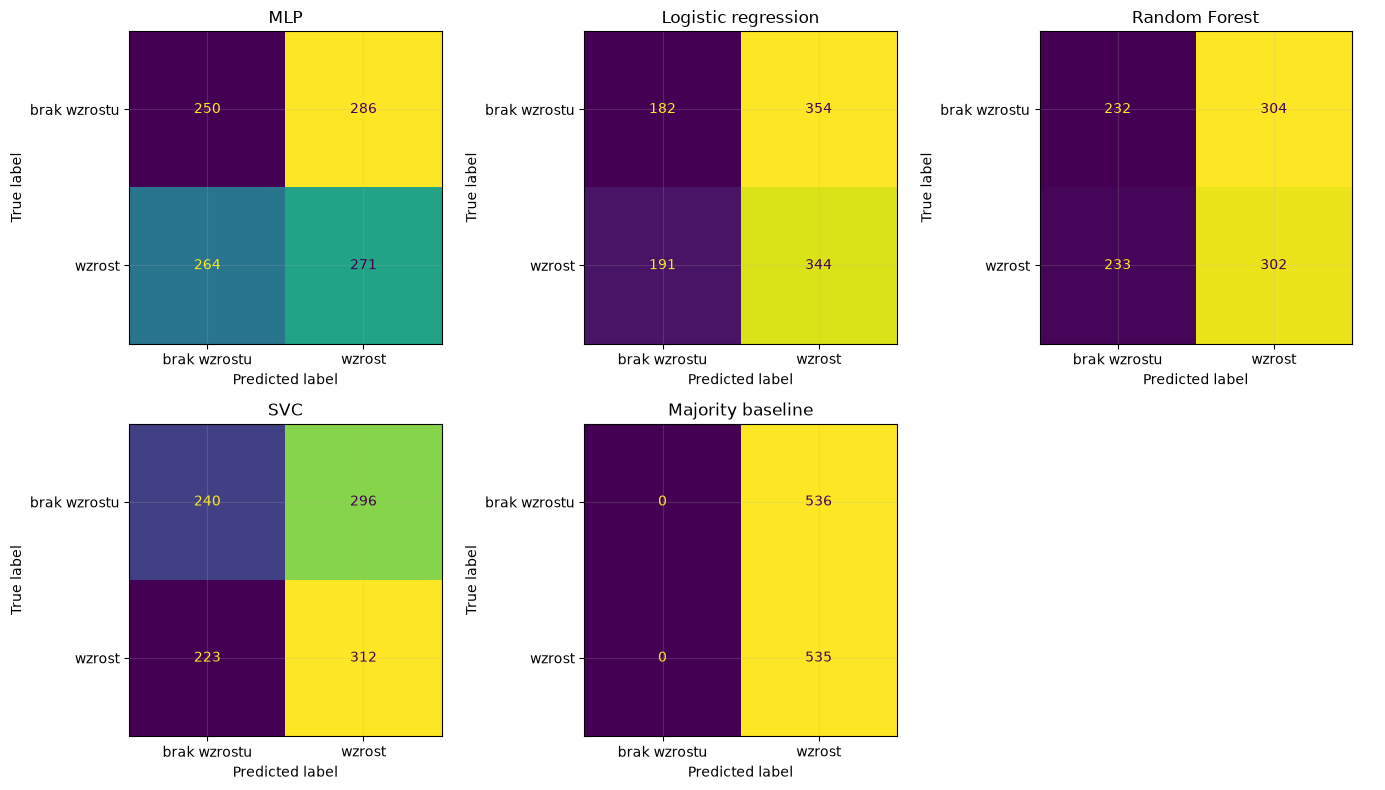

Raport MLP:
              precision    recall  f1-score   support

brak wzrostu       0.49      0.47      0.48       536
      wzrost       0.49      0.51      0.50       535

    accuracy                           0.49      1071
   macro avg       0.49      0.49      0.49      1071
weighted avg       0.49      0.49      0.49      1071



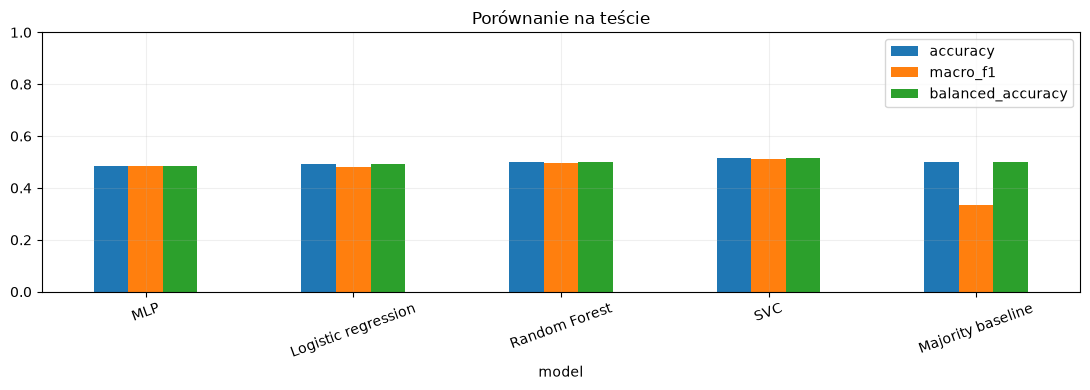

In [9]:
a_test = preprocessor.transform(X_test).astype('float32')
mlp_prob = mlp_probability(best_mlp, a_test)
predictions = {'MLP': (mlp_prob >= .5).astype(int)}
scores = {'MLP': mlp_prob}
for name, model in selected_models.items():
    predictions[name] = model.predict(X_test)
    if hasattr(model, 'decision_function'):
        scores[name] = model.decision_function(X_test)
    else:
        scores[name] = model.predict_proba(X_test)[:, 1]

rows = []
for name, pred in predictions.items():
    rows.append({'model': name, 'val_macro_f1': validation_scores[name],
                 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred, zero_division=0),
                 'recall': recall_score(y_test, pred, zero_division=0),
                 'f1': f1_score(y_test, pred, zero_division=0),
                 'macro_f1': f1_score(y_test, pred, average='macro', zero_division=0),
                 'balanced_accuracy': balanced_accuracy_score(y_test, pred),
                 'roc_auc': roc_auc_score(y_test, scores[name]) if y_test.nunique() == 2 else np.nan})
results = pd.DataFrame(rows).set_index('model')
display(results.round(4))
results.to_csv(RESULTS_DIR / 'test_metrics.csv')

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, pred) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=['brak wzrostu', 'wzrost'], ax=ax, colorbar=False)
    ax.set_title(name)
for ax in axes.flat[len(predictions):]:
    ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('Raport MLP:')
print(classification_report(y_test, predictions['MLP'], labels=[0, 1],
                            target_names=['brak wzrostu', 'wzrost'], zero_division=0))

results[['accuracy', 'macro_f1', 'balanced_accuracy']].plot.bar(ylim=(0, 1), rot=20,
                                                             title='Porównanie na teście')
plt.tight_layout()
plt.show()
export = pd.DataFrame({'target_date': label_date.loc[test_idx], 'y_true': y_test}, index=test_idx)
for name in predictions:
    export[name + '_pred'] = predictions[name]
    export[name + '_score'] = scores[name]
export.to_csv(RESULTS_DIR / 'test_predictions.csv', index_label='forecast_date')


## 9. Interpretacja wyników i ograniczenia

Poniższy komentarz jest generowany z wyników, a nie wpisany z góry.
Niewielka przewaga w jednym okresie testowym nie dowodzi trwałej zdolności prognostycznej.
Accuracy nie jest rentownością strategii; nie badamy spreadu, kosztów ani możliwości wykonania transakcji
po kursie referencyjnym. Również wysokie recall może wynikać z częstego przewidywania wzrostu:
trzeba odczytywać je razem z precision i macierzą pomyłek.


In [10]:
mlp_f1 = results.loc['MLP', 'macro_f1']
baseline_f1 = results.loc['Majority baseline', 'macro_f1']
print(f'MLP: accuracy={results.loc["MLP", "accuracy"]:.3f}, macro-F1={mlp_f1:.3f}.')
print(f'Różnica macro-F1 względem klasy większościowej: {mlp_f1 - baseline_f1:+.3f}.')
print(f'Model wybrany na walidacji: {selected_name}; jego testowy macro-F1: '
      f'{results.loc[selected_name, "macro_f1"]:.3f}.')
print('Najwyższy opisowy macro-F1 na tym teście:', results['macro_f1'].idxmax())
print('Ranking testowy opisuje ten okres; nie służy do ponownego strojenia modeli.')


MLP: accuracy=0.486, macro-F1=0.486.
Różnica macro-F1 względem klasy większościowej: +0.153.
Model wybrany na walidacji: MLP; jego testowy macro-F1: 0.486.
Najwyższy opisowy macro-F1 na tym teście: SVC
Ranking testowy opisuje ten okres; nie służy do ponownego strojenia modeli.


### Wniosek z wykonanego eksperymentu

W zapisanym uruchomieniu MLP osiągnął **48,65% accuracy**, Random Forest **49,86%**, regresja logistyczna **49,11%**, a SVC **51,54%**. Model większościowy uzyskał **49,95%**. MLP wybrano na walidacji, ale nie utrzymał przewagi na teście; najwyższy testowy macro-F1 miał SVC (0,513).

**Nie uzyskaliśmy przekonującego dowodu zdolności przewidywania kierunku zmian.** Niewielka przewaga SVC nad punktem odniesienia wymagałaby oceny niepewności i sprawdzenia na innych okresach. Nie dostrajamy modelu po obejrzeniu tego wyniku.

Przewaga macro-F1 sieci nad modelem większościowym (0,486 wobec 0,333) nie oznacza sama w sobie przewagi nad zgadywaniem: model większościowy ignoruje jedną klasę. Podobnie jego F1 dla wzrostów wynosi aż 0,666, mimo że zawsze przewiduje wzrost. To pokazuje, dlaczego potrzebne są również balanced accuracy, ROC-AUC i macierz pomyłek.

Wynik odpowiada na pytanie badawcze dla tego zestawu cech i podziału. Nie należy dobierać danych ani parametrów tylko po to, aby uzyskać efektowną accuracy. Naturalnym dalszym badaniem jest dodanie informacji rynkowych i walidacja walk-forward na nowym protokole eksperymentalnym.


## 10. Wnioski do sprawozdania i dalszej pracy

Po uruchomieniu odpowiedz własnymi słowami:
1. Czy klasy były zrównoważone? Jak to wpływa na interpretację accuracy?
2. Czy krzywe BCE wskazują przeuczenie? W której epoce zapisano najlepszy model?
3. Czy MLP przewyższył model większościowy i modele klasyczne? O ile, według macro-F1?
4. Jak zmienił się wynik modelu między walidacją a testem?
5. Czy model poprawnie rozpoznaje obie klasy, czy głównie jedną z nich?

**Powiązanie z magisterką:** przygotowanie cech, chronologia i kontrola wycieku można wykorzystać ponownie.
Kolejne eksperymenty to walk-forward na kilku okresach, kilka ziaren losowości i porównanie
EUR/USD-only z EUR/USD + dane rynkowe, a później + makro. Zmienne zewnętrzne należy łączyć
według momentu ich rzeczywistej dostępności, z uwzględnieniem rewizji.
Transformer będzie osobnym modelem; obecny MLP stanowi prosty benchmark.
Prognoza wartości stopy zwrotu w magisterce będzie zadaniem regresji, więc wymaga też innych metryk.

**Ograniczenia:** pojedynczy podział czasowy, mała siatka hiperparametrów, jeden seed,
brak przedziałów niepewności i formalnego testu przewagi. Walidacja służy jednocześnie
wyborowi epoki i konfiguracji; rozbudowane badanie powinno używać wielokrotnej walidacji czasowej.

**Źródła metod:**
- [PyTorch: BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
- [scikit-learn: unikanie data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [scikit-learn: metryki klasyfikacji](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)

Notebook pokrywa osiem punktów zadania. Wyniki i przewidywania są zapisywane w folderze `results/`.
